In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

files = sorted(glob.glob("Medicare_FFS_CERT_*.csv"))

df_list = []

for file in files:
    temp = pd.read_csv(file, low_memory=False)
    temp["Year"] = int(os.path.basename(file).replace("Medicare_FFS_CERT_", "").replace(".csv", ""))
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))
print("\nDescriptive statistics:")
print(df.describe(include="all").T)

Dataset shape: (2849279, 9)

Columns:
['claim_control_number', 'Part', 'DRG', 'HCPCS Procedure Code', 'Provider Type', 'Type of Bill', 'Review Decision', 'Error Code', 'Year']

Missing values:
DRG                     2498571
Type of Bill             862370
HCPCS Procedure Code     810780
Review Decision               1
claim_control_number          0
Part                          0
Provider Type                 0
Error Code                    0
Year                          0
dtype: int64

Descriptive statistics:
                          count unique  \
claim_control_number  2849279.0    NaN   
Part                    2849279      5   
DRG                    350708.0    NaN   
HCPCS Procedure Code    2038499  12850   
Provider Type           2849279    145   
Type of Bill            1986909    239   
Review Decision         2849278      2   
Error Code              2849279      7   
Year                  2849279.0    NaN   

                                                            

/var/folders/vs/_9xprskj13z9phq6nljg9lyh0000gn/T/ipykernel_29485/1768362952.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=decision_counts.index, y=decision_counts.values, palette=colors)


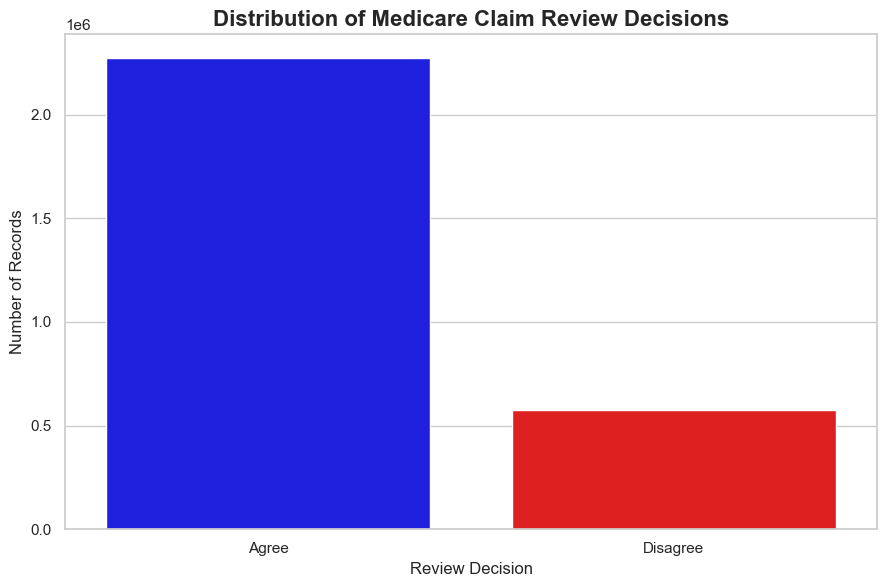

In [6]:
plt.figure(figsize=(9, 6))
decision_counts = df["Review Decision"].value_counts()
colors = ["blue" if decision == "Agree" else "red" for decision in decision_counts.index]

sns.barplot(x=decision_counts.index, y=decision_counts.values, palette=colors)
plt.title("Distribution of Medicare Claim Review Decisions", fontsize=16, weight="bold")
plt.xlabel("Review Decision")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

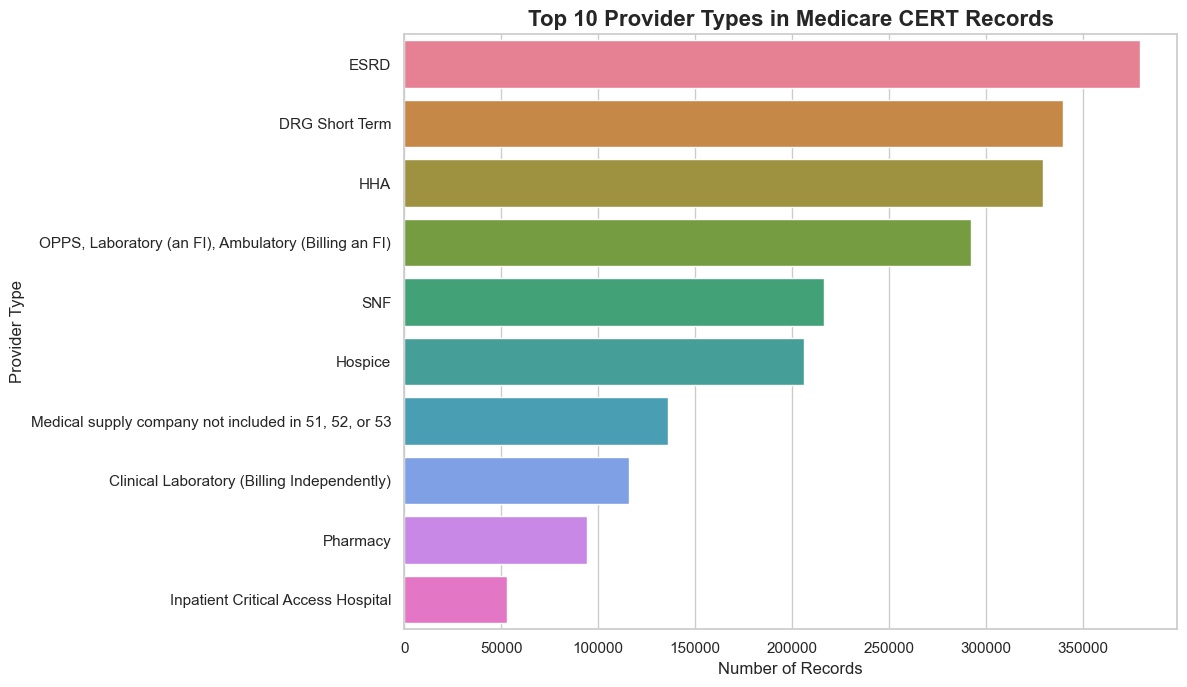

In [9]:
provider_counts = df["Provider Type"].value_counts().head(10)

colors = sns.color_palette("husl", n_colors=len(provider_counts))

plt.figure(figsize=(12, 7))
sns.barplot(
    x=provider_counts.values,
    y=provider_counts.index,
    hue=provider_counts.index,
    palette=colors,
    legend=False
)

plt.title("Top 10 Provider Types in Medicare CERT Records", fontsize=16, weight="bold")
plt.xlabel("Number of Records")
plt.ylabel("Provider Type")
plt.tight_layout()
plt.show()

In [13]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

DATA_FOLDER = "."
OUTPUT_FOLDER = "MFCU_graphs"

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

plt.style.use("ggplot")

In [16]:
FILES = [
    "FY_2010_MFCU_Statistical_Chart.xls",
    "FY_2011_MFCU_Statistical_Chart.xls",
    "FY_2012_MFCU_Statistical_Chart.xls",
    "FY_2013_MFCU_Statistical_Chart.xls",
    "FY_2014_MFCU_Statistical_Chart.xls",
    "FY_2015_MFCU_Statistical_Chart.xlsx",
    "FY_2016_MFCU_Statistical_Chart.xlsx",
    "FY_2017_MFCU_Statistical_Chart.xlsx",
    "FY_2018_MFCU_Statistical_Chart.xlsx",
    "FY_2019_MFCU_Statistical_Chart.xlsx",
    "FY_2020_MFCU_Statistical_Chart.xlsx",
    "FY_2021_MFCU_Statistical_Chart.xlsx",
    "FY_2022_MFCU_Statistical_Chart.xlsx",
    "FY_2023_MFCU_Statistical_Chart.xlsx",
    "FY2024 Statistical Chart_Table_protected.xlsx"
]

In [19]:
def clean_name(name):
    return re.sub(r"[^a-z]", "", str(name).lower())


def find_col(columns, target):
    target = clean_name(target)

    for col in columns:
        if clean_name(col) == target:
            return col

    for col in columns:
        if target in clean_name(col):
            return col

    return None


def load_file(filename):
    path = os.path.join(DATA_FOLDER, filename)

    if not os.path.exists(path):
        print("Missing file:", filename)
        return None

    engine = "xlrd" if filename.endswith(".xls") else "openpyxl"

    raw = pd.read_excel(path, header=None, engine=engine)

    header_row = None

    for i in range(min(25, len(raw))):
        values = [clean_name(x) for x in raw.iloc[i].tolist()]

        if (
            "state" in values
            and any("fraudinvestigations" in x for x in values)
            and any("totalrecoveries" in x for x in values)
        ):
            header_row = i
            break

    if header_row is None:
        print("Header not found:", filename)
        return None

    df = raw.iloc[header_row + 1:].copy()
    df.columns = raw.iloc[header_row].astype(str).str.strip()
    df = df.loc[:, ~df.columns.duplicated()]

    state_col = find_col(df.columns, "State")

    if state_col is None:
        return None

    df[state_col] = df[state_col].astype(str).str.strip()

    df = df[
        ~df[state_col].str.lower().isin(
            ["total", "grand total", "nan", ""]
        )
    ]

    mappings = {
        "Fraud Investigations": "Fraud Investigations",
        "Fraud Indictments": "Fraud Indictments",
        "Fraud Convictions": "Fraud Convictions",
        "Total Recoveries": "Total Recoveries",
        "Grant Expenditures": "MFCU Grant Expenditures",
        "Medicaid Expenditures": "Total Medicaid Expenditures",
        "Staff": "Staff On Board"
    }

    year_match = re.search(r"20\d{2}", filename)

    if not year_match:
        return None

    result = {"Year": int(year_match.group())}

    for output_name, source_name in mappings.items():
        col = find_col(df.columns, source_name)

        if col is None:
            result[output_name] = None
        else:
            values = (
                df[col].astype(str)
                .str.replace(r"[$,\s]", "", regex=True)
                .str.replace(r"^\((.*)\)$", r"-\1", regex=True)
            )

            result[output_name] = pd.to_numeric(
                values, errors="coerce"
            ).sum(min_count=1)

    return result

In [22]:
records = []

for filename in FILES:
    try:
        data = load_file(filename)

        if data is not None:
            records.append(data)

    except Exception as error:
        print("Error reading", filename, ":", error)

if not records:
    raise ValueError(
        "No datasets loaded. Check your folder path and Excel files."
    )

annual = pd.DataFrame(records).sort_values("Year")

annual = annual.groupby(
    "Year", as_index=False
).sum(numeric_only=True)

annual.to_csv(
    os.path.join(OUTPUT_FOLDER, "MFCU_Annual_Summary.csv"),
    index=False
)

print(annual.to_string(index=False))

Error reading FY_2010_MFCU_Statistical_Chart.xls : Missing optional dependency 'xlrd'. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install xlrd.
Error reading FY_2011_MFCU_Statistical_Chart.xls : Missing optional dependency 'xlrd'. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install xlrd.
Error reading FY_2012_MFCU_Statistical_Chart.xls : Missing optional dependency 'xlrd'. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install xlrd.
Error reading FY_2013_MFCU_Statistical_Chart.xls : Missing optional dependency 'xlrd'. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install xlrd.
Error reading FY_2014_MFCU_Statistical_Chart.xls : Missing optional dependency 'xlrd'. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install xlrd.
 Year  Fraud Investigations  Fraud Indictments  Fraud Convictions  Total Recoveries  Grant Expenditures  Medicaid Expenditures  Staff
 2015               14441.0             1

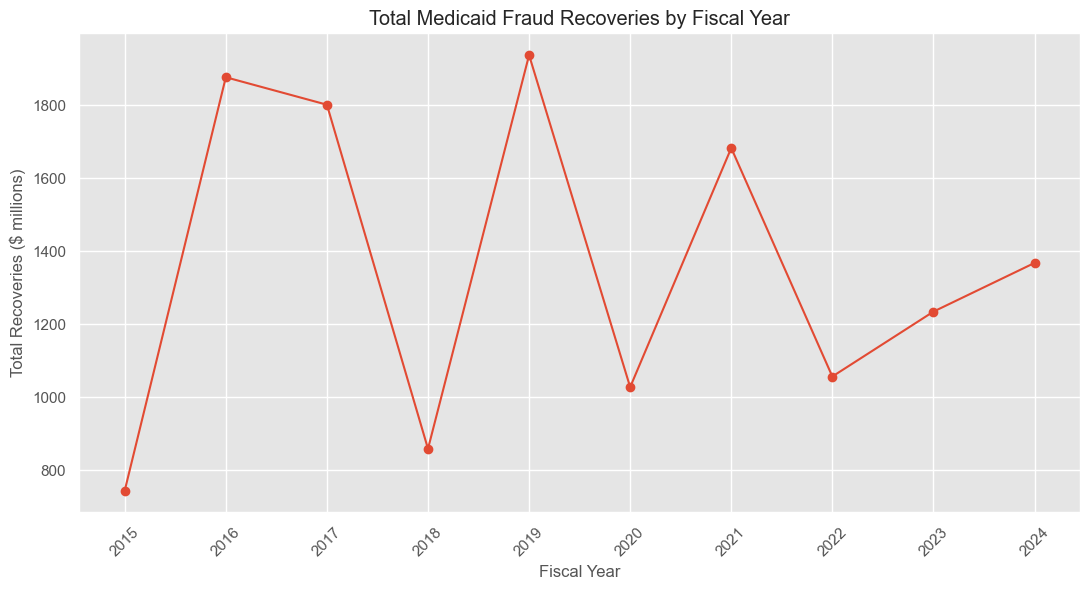

In [25]:
plt.figure(figsize=(11, 6))

plt.plot(
    annual["Year"],
    annual["Total Recoveries"] / 1_000_000,
    marker="o"
)

plt.title("Total Medicaid Fraud Recoveries by Fiscal Year")
plt.xlabel("Fiscal Year")
plt.ylabel("Total Recoveries ($ millions)")
plt.xticks(annual["Year"], rotation=45)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_FOLDER, "01_Total_Recoveries.png"),
    dpi=300
)
plt.show()
plt.close()

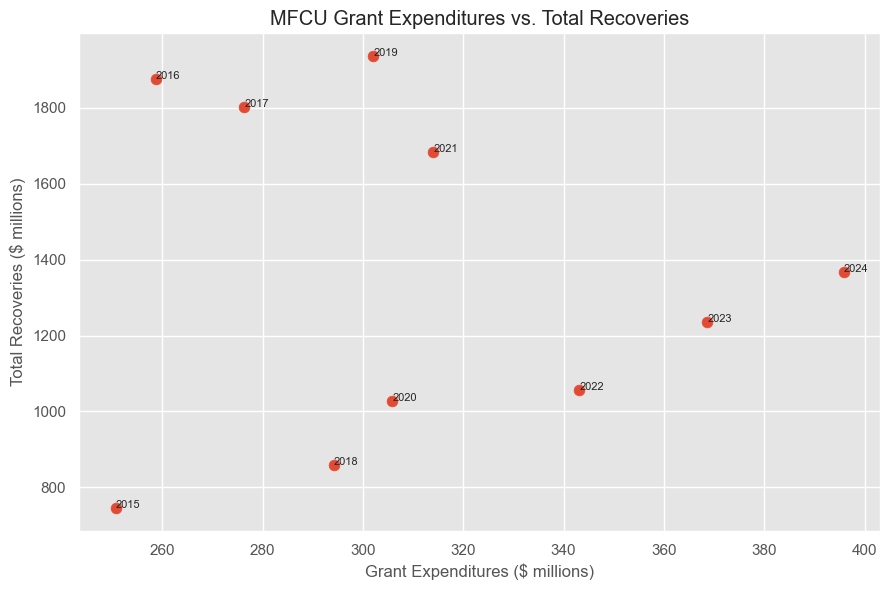

In [28]:
plt.figure(figsize=(9, 6))

x = annual["Grant Expenditures"] / 1_000_000
y = annual["Total Recoveries"] / 1_000_000

plt.scatter(x, y, s=60)

for _, row in annual.iterrows():
    if pd.notna(row["Grant Expenditures"]) and pd.notna(row["Total Recoveries"]):
        plt.annotate(
            str(int(row["Year"])),
            (
                row["Grant Expenditures"] / 1_000_000,
                row["Total Recoveries"] / 1_000_000
            ),
            fontsize=8
        )

plt.title("MFCU Grant Expenditures vs. Total Recoveries")
plt.xlabel("Grant Expenditures ($ millions)")
plt.ylabel("Total Recoveries ($ millions)")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_FOLDER, "03_Grant_Expenditures_vs_Recoveries.png"),
    dpi=300
)
plt.show()
plt.close()

Number of overpayment records: 605
Number of states: 43
Total reported overpayments: $4,589,651,366.93

Summary statistics:
count    6.050000e+02
mean     7.586201e+06
std      3.292535e+07
min      0.000000e+00
25%      1.609000e+03
50%      1.791420e+05
75%      1.475837e+06
max      3.524480e+08
Name: Response, dtype: float64

Overpayment records by state:
                      Number of Records  Total Reported Overpayments  Average Reported Overpayment
State                                                                                             
Texas                                37                 2.590737e+09                  7.001992e+07
Florida                              20                 4.289187e+08                  2.144594e+07
California                          121                 2.565896e+08                  2.120575e+06
New York                             54                 1.900791e+08                  3.519984e+06
Washington                            6     

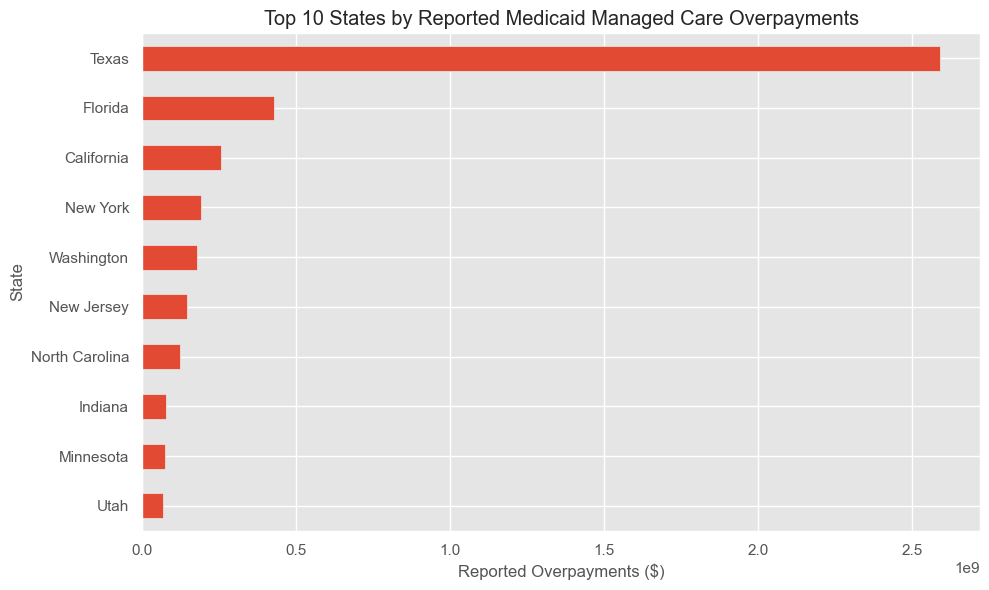

In [31]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("mmcc-mcpar-puf-2024.csv", low_memory=False)

df.columns = df.columns.str.strip()

overpayments = df[
    df["Question_ID"].astype(str).str.strip()
    == "plan_overpaymentReportingToStateDollarAmount"
].copy()

overpayments["Response"] = (
    overpayments["Response"]
    .astype(str)
    .str.replace(r"[$,]", "", regex=True)
    .str.strip()
)

overpayments["Response"] = pd.to_numeric(
    overpayments["Response"], errors="coerce"
)

overpayments = overpayments.dropna(subset=["Response"])

print("Number of overpayment records:", len(overpayments))
print("Number of states:", overpayments["State"].nunique())
print("Total reported overpayments: ${:,.2f}".format(
    overpayments["Response"].sum()
))

print("\nSummary statistics:")
print(overpayments["Response"].describe())

print("\nOverpayment records by state:")
state_totals = (
    overpayments.groupby("State")["Response"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
)

state_totals.columns = [
    "Number of Records",
    "Total Reported Overpayments",
    "Average Reported Overpayment"
]

print(state_totals.to_string())

print("\nTop 10 plans by reported overpayment:")
plan_totals = (
    overpayments.groupby(["State", "Plan_or_BSS"])["Response"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(plan_totals.to_string())

top_states = state_totals.head(10).sort_values(
    "Total Reported Overpayments"
)

top_states["Total Reported Overpayments"].plot(
    kind="barh", figsize=(10, 6)
)

plt.xlabel("Reported Overpayments ($)")
plt.ylabel("State")
plt.title("Top 10 States by Reported Medicaid Managed Care Overpayments")
plt.tight_layout()
plt.show()
